In [1]:
import torch

print("PyTorch:", torch.__version__)
print("CUDA:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.9.1+cu128
CUDA: True
GPU: Tesla V100-PCIE-32GB


In [12]:
from ultralytics import YOLO

In [13]:
import os

dataset_path = "Mushroom-Growth-Stages"

print(os.listdir(dataset_path))

['train', 'data.yaml', 'test', '.ipynb_checkpoints', 'valid']


In [14]:
with open("Mushroom-Growth-Stages/data.yaml") as f:
    print(f.read())

train: ../train/images
val: ../valid/images
test: ../test/images

nc: 3
names: ['Harvest', 'Intermediate', 'Juvenile']

roboflow:
  workspace: franciis
  project: mushroom-growth-stages-2vmfq
  version: 3
  license: CC BY 4.0
  url: https://universe.roboflow.com/franciis/mushroom-growth-stages-2vmfq/dataset/3


In [5]:
from ultralytics import YOLO

model = YOLO("yolov8n.pt")

results = model.train(
    data="Mushroom-Growth-Stages/data.yaml",
    epochs=100,
    imgsz=640,
    batch=32,
    device=0,
    workers=8,
    project="Mushroom_Project",
    name="Growth_Stages"
)

New https://pypi.org/project/ultralytics/8.4.115 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.17 🚀 Python-3.13.5 torch-2.9.1+cu128 CUDA:0 (Tesla V100-PCIE-32GB, 32494MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=Mushroom-Growth-Stages/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=G

In [6]:
from ultralytics import YOLO

# Load the trained model
model = YOLO("runs/detect/Mushroom_Project/Growth_Stages2/weights/best.pt")  # Change the path if needed

# Validate the model
metrics = model.val()

# Print the four evaluation metrics
print(f"Precision : {metrics.box.mp:.4f}")
print(f"Recall    : {metrics.box.mr:.4f}")
print(f"mAP@50    : {metrics.box.map50:.4f}")
print(f"mAP@50-95 : {metrics.box.map:.4f}")

Ultralytics 8.4.17 🚀 Python-3.13.5 torch-2.9.1+cu128 CUDA:0 (Tesla V100-PCIE-32GB, 32494MiB)
Model summary (fused): 73 layers, 3,006,233 parameters, 0 gradients
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1664.3±246.7 MB/s, size: 61.4 KB)
val: Scanning /home/anishkrishnas.23cse/23ECR161/Mushroom-Growth-Stages/valid/labels.cache... 693 images, 1 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 693/693 264.2Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 44/44 1.6it/s 27.6s0.7ss
                   all        693        888      0.865      0.844      0.925      0.766
               Harvest        360        433      0.884        0.9      0.953      0.797
          Intermediate        246        292      0.869      0.841      0.923      0.781
              Juvenile        150        163      0.843      0.791      0.898      0.718
Speed: 1.2ms preprocess, 3.2ms inference, 0.0ms loss, 6.1ms postprocess per image
Results sa

In [9]:
from ultralytics import YOLO

# Load the trained model
model = YOLO("runs/detect/Mushroom_Project/Growth_Stages2/weights/best.pt")   # Change path if needed

# Predict on all test images
results = model.predict(
    source="Mushroom-Growth-Stages/test/images",   # Path to your test images
    imgsz=640,
    conf=0.25,
    save=True
)

print("Prediction completed!")


image 1/338 /home/anishkrishnas.23cse/23ECR161/Mushroom-Growth-Stages/test/images/IMG_1578_mov-0461_jpg.rf.23aae61687ca2f9719b2803d5827eab5.jpg: 640x640 1 Intermediate, 7.2ms
image 2/338 /home/anishkrishnas.23cse/23ECR161/Mushroom-Growth-Stages/test/images/IMG_1578_mov-0487_jpg.rf.bb85b8fb90ea2c10ddd91e85f6cb1369.jpg: 640x640 1 Harvest, 7.2ms
image 3/338 /home/anishkrishnas.23cse/23ECR161/Mushroom-Growth-Stages/test/images/IMG_1578_mov-0548_jpg.rf.71b02deaf7a80da577da7f399a5c0b89.jpg: 640x640 1 Intermediate, 1 Juvenile, 7.6ms
image 4/338 /home/anishkrishnas.23cse/23ECR161/Mushroom-Growth-Stages/test/images/IMG_1578_mov-0588_jpg.rf.554e1a1ab0dd5aa46ecb5ef1f1cfba0a.jpg: 640x640 1 Harvest, 1 Juvenile, 7.2ms
image 5/338 /home/anishkrishnas.23cse/23ECR161/Mushroom-Growth-Stages/test/images/IMG_1578_mov-0633_jpg.rf.f4337c4528fd5dadd8f5049d93e6dcef.jpg: 640x640 1 Harvest, 7.5ms
image 6/338 /home/anishkrishnas.23cse/23ECR161/Mushroom-Growth-Stages/test/images/IMG_1578_mov-0638_jpg.rf.96e54a96

In [5]:
from ultralytics import YOLO
from IPython.display import Image, display

model = YOLO("runs/detect/Mushroom_Project/Growth_Stages2/weights/best.pt")

results = model.predict(
    source="images.jpg",   # Replace with your image name
    imgsz=640,
    conf=0.25,
    save=True
)




image 1/1 /home/anishkrishnas.23cse/23ECR161/images.jpg: 448x640 1 Harvest, 33.7ms
Speed: 1.5ms preprocess, 33.7ms inference, 0.9ms postprocess per image at shape (1, 3, 448, 640)
Results saved to /home/anishkrishnas.23cse/23ECR161/runs/detect/predict17


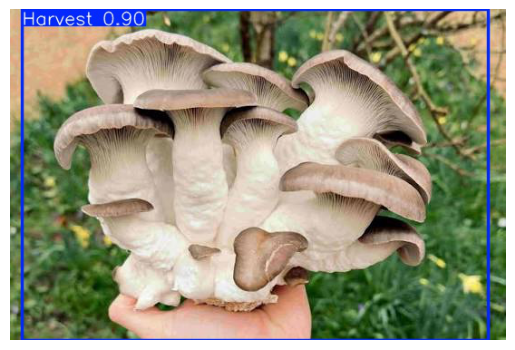

In [6]:
import glob, matplotlib.pyplot as plt; from PIL import Image; plt.imshow(Image.open(glob.glob("runs/detect/predict17/*")[0])); plt.axis("off"); plt.show()


Mushroom : 1
Growth Stage     : Harvest
YOLO Confidence  : 89.6%
Green abnormal   : 0.00%
Brown abnormal   : 2.18%
Dark abnormal    : 1.80%
Total abnormal   : 3.70%
Health Status    : Healthy


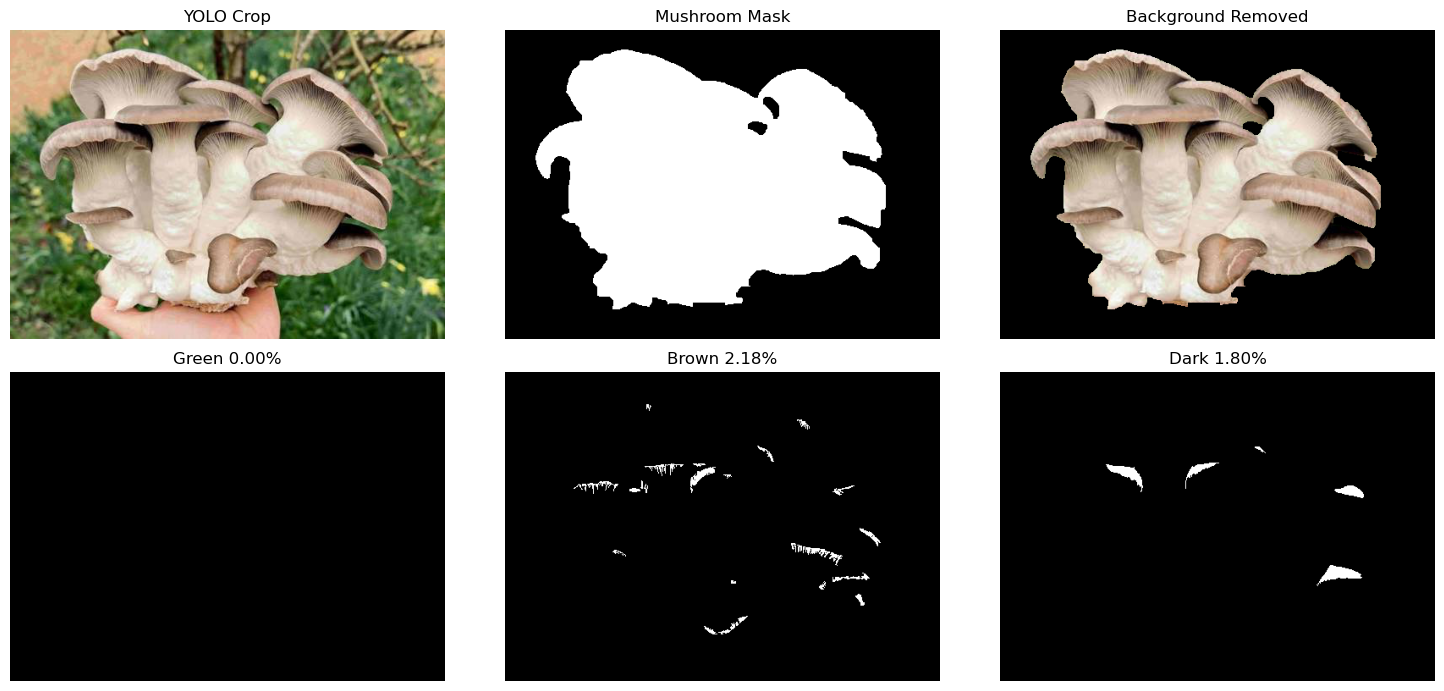

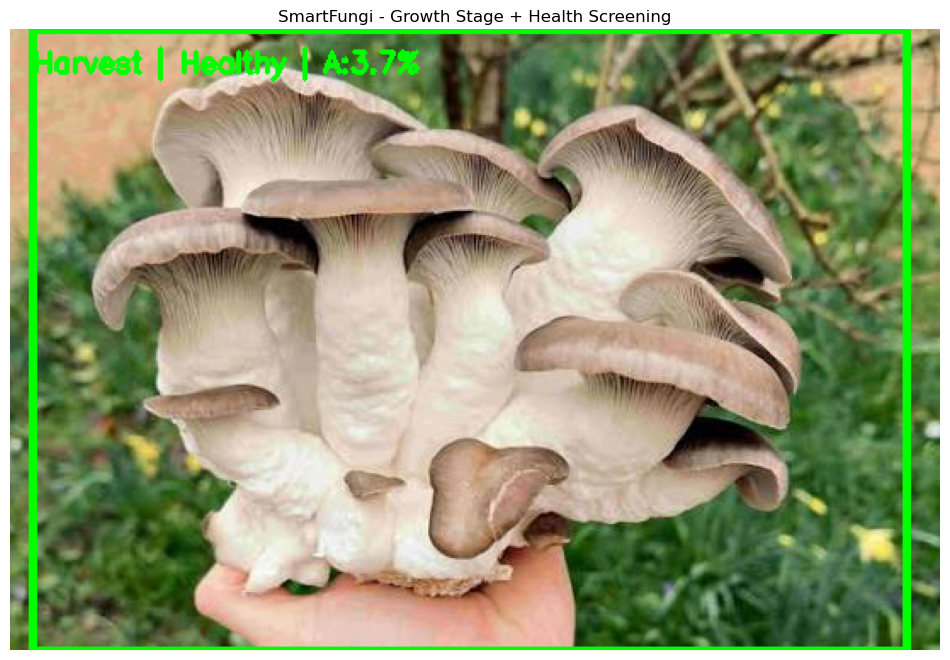

In [7]:
# ============================================================
# SMARTFUNGI: GROWTH STAGE + COLOUR-BASED DISEASE SCREENING
# ============================================================

import cv2
import numpy as np
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# SETTINGS
# ------------------------------------------------------------

# Experimental threshold - tune using healthy/infected samples
ABNORMAL_THRESHOLD = 8.0

# Minimum connected coloured region to consider
MIN_AREA = 20


# ------------------------------------------------------------
# Remove very small colour spots/noise
# ------------------------------------------------------------
def remove_small_regions(mask, min_area=20):

    n, labels, stats, _ = cv2.connectedComponentsWithStats(
        mask,
        connectivity=8
    )

    cleaned = np.zeros_like(mask)

    for i in range(1, n):

        area = stats[i, cv2.CC_STAT_AREA]

        if area >= min_area:
            cleaned[labels == i] = 255

    return cleaned


# ------------------------------------------------------------
# Background removal
# ------------------------------------------------------------
def remove_background(crop):

    h, w = crop.shape[:2]

    mask = np.zeros((h, w), np.uint8)

    bg_model = np.zeros((1, 65), np.float64)
    fg_model = np.zeros((1, 65), np.float64)

    margin = max(2, min(h, w) // 50)

    rect = (
        margin,
        margin,
        max(1, w - 2 * margin),
        max(1, h - 2 * margin)
    )

    cv2.grabCut(
        crop,
        mask,
        rect,
        bg_model,
        fg_model,
        5,
        cv2.GC_INIT_WITH_RECT
    )

    mushroom_mask = np.where(
        (mask == cv2.GC_FGD) |
        (mask == cv2.GC_PR_FGD),
        255,
        0
    ).astype("uint8")

    # Clean mask
    kernel = np.ones((3, 3), np.uint8)

    mushroom_mask = cv2.morphologyEx(
        mushroom_mask,
        cv2.MORPH_OPEN,
        kernel
    )

    mushroom_mask = cv2.morphologyEx(
        mushroom_mask,
        cv2.MORPH_CLOSE,
        kernel
    )

    # Slight erosion removes background at edges
    mushroom_mask = cv2.erode(
        mushroom_mask,
        kernel,
        iterations=1
    )

    mushroom_only = cv2.bitwise_and(
        crop,
        crop,
        mask=mushroom_mask
    )

    return mushroom_only, mushroom_mask


# ------------------------------------------------------------
# Colour-based abnormality detection
# ------------------------------------------------------------
def disease_detection(crop, mushroom_mask):

    hsv = cv2.cvtColor(crop, cv2.COLOR_BGR2HSV)

    # ---------------- GREEN ----------------
    green_mask = cv2.inRange(
        hsv,
        np.array([35, 70, 40]),
        np.array([90, 255, 220])
    )

    # ---------------- BROWN ----------------
    # High saturation requirement avoids normal cream colours
    brown_mask = cv2.inRange(
        hsv,
        np.array([5, 120, 20]),
        np.array([25, 255, 160])
    )

    # ---------------- BLACK / DARK ----------------
    dark_mask = cv2.inRange(
        hsv,
        np.array([0, 0, 0]),
        np.array([179, 255, 40])
    )

    # ------------------------------------------------
    # Keep ONLY pixels inside mushroom region
    # ------------------------------------------------
    green_mask = cv2.bitwise_and(
        green_mask,
        mushroom_mask
    )

    brown_mask = cv2.bitwise_and(
        brown_mask,
        mushroom_mask
    )

    dark_mask = cv2.bitwise_and(
        dark_mask,
        mushroom_mask
    )

    # Remove tiny noise
    green_mask = remove_small_regions(
        green_mask,
        MIN_AREA
    )

    brown_mask = remove_small_regions(
        brown_mask,
        MIN_AREA
    )

    dark_mask = remove_small_regions(
        dark_mask,
        MIN_AREA
    )

    # Mushroom pixels only
    total_mushroom_pixels = cv2.countNonZero(
        mushroom_mask
    )

    if total_mushroom_pixels == 0:

        return (
            0, 0, 0, 0,
            "Unknown",
            green_mask,
            brown_mask,
            dark_mask
        )

    # Percentage calculations
    green_percent = (
        cv2.countNonZero(green_mask)
        / total_mushroom_pixels
    ) * 100

    brown_percent = (
        cv2.countNonZero(brown_mask)
        / total_mushroom_pixels
    ) * 100

    dark_percent = (
        cv2.countNonZero(dark_mask)
        / total_mushroom_pixels
    ) * 100

    # Combine abnormal colours
    abnormal_mask = cv2.bitwise_or(
        green_mask,
        brown_mask
    )

    abnormal_mask = cv2.bitwise_or(
        abnormal_mask,
        dark_mask
    )

    abnormal_percent = (
        cv2.countNonZero(abnormal_mask)
        / total_mushroom_pixels
    ) * 100

    # ------------------------------------------------
    # Health decision
    # ------------------------------------------------
    if abnormal_percent > ABNORMAL_THRESHOLD:

        health = "Infection Suspected"

    else:

        health = "Healthy"

    return (
        green_percent,
        brown_percent,
        dark_percent,
        abnormal_percent,
        health,
        green_mask,
        brown_mask,
        dark_mask
    )


# ============================================================
# PROCESS YOLO RESULTS
# ============================================================

original = results[0].orig_img.copy()

final_img = original.copy()


for number, box in enumerate(results[0].boxes, start=1):

    # YOLO bounding box
    x1, y1, x2, y2 = map(
        int,
        box.xyxy[0]
    )

    # Growth stage
    class_id = int(box.cls[0])

    stage = model.names[class_id]

    confidence = float(box.conf[0])

    # Crop detected mushroom
    crop = original[
        y1:y2,
        x1:x2
    ].copy()

    if crop.size == 0:
        continue

    # --------------------------------------------------------
    # REMOVE BACKGROUND
    # --------------------------------------------------------
    mushroom_only, mushroom_mask = remove_background(
        crop
    )

    # --------------------------------------------------------
    # DISEASE / COLOUR ANALYSIS
    # --------------------------------------------------------
    (
        green,
        brown,
        dark,
        abnormal,
        health,
        green_mask,
        brown_mask,
        dark_mask

    ) = disease_detection(
        crop,
        mushroom_mask
    )

    # --------------------------------------------------------
    # PRINT RESULTS
    # --------------------------------------------------------

    print("\n==============================")
    print("Mushroom :", number)
    print("==============================")

    print(
        f"Growth Stage     : {stage}"
    )

    print(
        f"YOLO Confidence  : {confidence*100:.1f}%"
    )

    print(
        f"Green abnormal   : {green:.2f}%"
    )

    print(
        f"Brown abnormal   : {brown:.2f}%"
    )

    print(
        f"Dark abnormal    : {dark:.2f}%"
    )

    print(
        f"Total abnormal   : {abnormal:.2f}%"
    )

    print(
        f"Health Status    : {health}"
    )

    # --------------------------------------------------------
    # FINAL BOUNDING BOX
    # --------------------------------------------------------

    if health == "Healthy":

        color = (0, 255, 0)

    else:

        color = (0, 0, 255)

    cv2.rectangle(
        final_img,
        (x1, y1),
        (x2, y2),
        color,
        3
    )

    text = (
        f"{stage} | {health} | "
        f"A:{abnormal:.1f}%"
    )

    cv2.putText(
        final_img,
        text,
        (x1, max(25, y1 - 10)),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.55,
        color,
        2
    )

    # --------------------------------------------------------
    # SHOW INTERNAL PROCESS
    # --------------------------------------------------------

    plt.figure(figsize=(15, 7))

    plt.subplot(2, 3, 1)

    plt.imshow(
        cv2.cvtColor(
            crop,
            cv2.COLOR_BGR2RGB
        )
    )

    plt.title("YOLO Crop")
    plt.axis("off")


    plt.subplot(2, 3, 2)

    plt.imshow(
        mushroom_mask,
        cmap="gray"
    )

    plt.title("Mushroom Mask")
    plt.axis("off")


    plt.subplot(2, 3, 3)

    plt.imshow(
        cv2.cvtColor(
            mushroom_only,
            cv2.COLOR_BGR2RGB
        )
    )

    plt.title("Background Removed")
    plt.axis("off")


    plt.subplot(2, 3, 4)

    plt.imshow(
        green_mask,
        cmap="gray"
    )

    plt.title(
        f"Green {green:.2f}%"
    )

    plt.axis("off")


    plt.subplot(2, 3, 5)

    plt.imshow(
        brown_mask,
        cmap="gray"
    )

    plt.title(
        f"Brown {brown:.2f}%"
    )

    plt.axis("off")


    plt.subplot(2, 3, 6)

    plt.imshow(
        dark_mask,
        cmap="gray"
    )

    plt.title(
        f"Dark {dark:.2f}%"
    )

    plt.axis("off")

    plt.tight_layout()
    plt.show()


# ============================================================
# FINAL OUTPUT
# ============================================================

plt.figure(figsize=(12, 9))

plt.imshow(
    cv2.cvtColor(
        final_img,
        cv2.COLOR_BGR2RGB
    )
)

plt.title(
    "SmartFungi - Growth Stage + Health Screening"
)

plt.axis("off")

plt.show()